# Car Price Prediction with Machine Learning

## 1. Project Overview

The objective of this project is to explore a car dataset,
prepare the available features, train regression models,
and evaluate their ability to predict car selling prices.

The analysis will be based on the actual dataset and
measured model performance.

## 2. Dataset Loading and Initial Inspection

### 2.1 Importing Required Libraries

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print("Python executable:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

Python executable: c:\Users\Faraz Ibrahim\codealpha-data-science-internship\.venv\Scripts\python.exe
Pandas: 3.0.6
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
Scikit-learn: 1.9.1


### 2.2 Checking the Dataset Path

In [2]:
from pathlib import Path

data_path = Path("../data/car data.csv")

print("Notebook working directory:", Path.cwd())
print("Dataset path:", data_path.resolve())
print("Dataset exists:", data_path.exists())

Notebook working directory: c:\Users\Faraz Ibrahim\codealpha-data-science-internship\Task_3_Car_Price_Prediction_with_Machine_Learning\notebooks
Dataset path: C:\Users\Faraz Ibrahim\codealpha-data-science-internship\Task_3_Car_Price_Prediction_with_Machine_Learning\data\car data.csv
Dataset exists: True


### 2.3 Loading the Dataset

In [3]:
df = pd.read_csv(data_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


### 2.4 Previewing the Dataset

In [4]:
print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


### 2.5 Understanding Dataset Structure

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Selling_type   301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


### 2.6 Initial Dataset Overview

The dataset contains 301 rows and 9 columns. It includes numerical and categorical features describing car characteristics, prices, and selling conditions.

The Selling_Price column is the proposed target variable for the regression task. The Id column is not present in this dataset; instead, Car_Name identifies the car model or name.

The initial inspection reports 301 non-null values in each column. Missing-value checks and other data quality assessments will be performed in the next section.

## 3. Data Quality Checks

### 3.1 Checking for Missing Values

In [6]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:


Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


Total missing values: 0


#### Missing Values - Findings

- The dataset contains no missing values according to `df.isnull().sum()`.
- All nine columns have 301 non-null observations.
- No missing-value imputation or row removal is required at this stage.
- Other data quality checks are still necessary because missing-value checks do not identify duplicate records, inconsistent categories, or invalid numerical values.

### 3.2 Checking for Duplicate Records

Duplicate records may occur when the same observation appears more than once in a dataset. Such records can affect descriptive statistics and may influence the training of a machine learning model.

The `duplicated()` method will be used to identify rows that exactly match previously occurring rows across all columns. The duplicate records will be inspected before deciding whether any action is necessary.

In [7]:
# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Display duplicate rows for inspection
duplicate_records = df[df.duplicated(keep=False)]

display(duplicate_records.sort_values(by=df.columns.tolist()))

Number of duplicate rows: 2


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
15,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0


### 3.3 Checking Categorical Feature Values

Categorical features describe vehicle characteristics using labels rather than continuous numerical measurements.

The `Fuel_Type`, `Selling_type`, and `Transmission` columns will be examined to identify the available categories and their frequencies. The `Car_Name` column will also be inspected to understand the variety of car names represented in the dataset.

This check helps identify unexpected category labels, inconsistent formatting, or categories with very few observations.

In [8]:
# Identify the distinct values and their frequencies
categorical_columns = [
    "Fuel_Type",
    "Selling_type",
    "Transmission",
    "Car_Name"
]

for column in categorical_columns:
    print(f"\nValue counts for {column}:")
    display(df[column].value_counts(dropna=False))

# Inspect the distinct values in each categorical column
for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(df[column].unique())


Value counts for Fuel_Type:


Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64


Value counts for Selling_type:


Selling_type
Dealer        195
Individual    106
Name: count, dtype: int64


Value counts for Transmission:


Transmission
Manual       261
Automatic     40
Name: count, dtype: int64


Value counts for Car_Name:


Car_Name
city                   26
corolla altis          16
verna                  14
fortuner               11
brio                   10
                       ..
Hero Super Splendor     1
Hero Hunk               1
Hero  Ignitor Disc      1
Hero  CBZ Xtreme        1
Bajaj  ct 100           1
Name: count, Length: 98, dtype: int64


Unique values in Fuel_Type:
<StringArray>
['Petrol', 'Diesel', 'CNG']
Length: 3, dtype: str

Unique values in Selling_type:
<StringArray>
['Dealer', 'Individual']
Length: 2, dtype: str

Unique values in Transmission:
<StringArray>
['Manual', 'Automatic']
Length: 2, dtype: str

Unique values in Car_Name:
<StringArray>
[                     'ritz',                       'sx4',
                      'ciaz',                   'wagon r',
                     'swift',             'vitara brezza',
                   's cross',                  'alto 800',
                    'ertiga',                     'dzire',
                  'alto k10',                     'ignis',
                       '800',                    'baleno',
                      'omni',                  'fortuner',
                    'innova',             'corolla altis',
               'etios cross',                   'etios g',
                'etios liva',                   'corolla',
                  'etios gd',  

### 3.4 Examining Numerical Values and Data Ranges

Numerical features will be examined using descriptive statistics to understand their ranges and identify potentially suspicious values.

Particular attention will be given to `Year`, `Selling_Price`, `Present_Price`, `Driven_kms`, and `Owner`. These columns represent the manufacturing year, selling price, present price, distance driven, and recorded owner count, respectively, based on their names and the dataset structure.

The descriptive statistics will help identify negative values, implausible measurements, or unusually large observations that require further investigation. Unusual values will not be removed automatically because they may represent genuine vehicles.

In [9]:
# Select all numerical columns
numerical_columns = df.select_dtypes(include="number").columns

# Display descriptive statistics
display(df[numerical_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Year,301.0,2013.627907,2.891554,2003.00,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,4.661296,5.082812,0.10,0.9,3.6,6.0,35.0
Present_Price,301.0,7.628472,8.642584,0.32,1.2,6.4,9.9,92.6
Driven_kms,301.0,36947.205980,38886.883882,500.00,15000.0,32000.0,48767.0,500000.0
Owner,301.0,0.043189,0.247915,0.00,0.0,0.0,0.0,3.0


In [10]:
# Check for potentially invalid numerical values
print("Years before 1900:")
display(df[df["Year"] < 1900])

print("Negative selling prices:")
display(df[df["Selling_Price"] < 0])

print("Non-positive present prices:")
display(df[df["Present_Price"] <= 0])

print("Negative distances driven:")
display(df[df["Driven_kms"] < 0])

print("Negative owner counts:")
display(df[df["Owner"] < 0])

Years before 1900:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner


Negative selling prices:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner


Non-positive present prices:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner


Negative distances driven:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner


Negative owner counts:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner


### 3.5 Checking Data Types and Dataset Consistency

The data types of the dataset will be reviewed to confirm that numerical measurements are stored as numerical values and categorical attributes are stored in suitable formats.

The initial inspection showed that the dataset contains integer, floating-point, and string columns. This section will also check for whitespace around categorical labels and identify any remaining missing values after the initial inspection.

These checks help establish whether the dataset is structurally suitable for further exploratory analysis and preprocessing.

In [11]:
# Display the data types of all columns
print("Data types:")
display(df.dtypes)

# Check for leading or trailing whitespace in string values
string_columns = df.select_dtypes(include=["object", "str"]).columns

print("Whitespace checks:")

for column in string_columns:
    whitespace_count = (
        df[column].dropna()
        .astype(str)
        .ne(df[column].dropna().astype(str).str.strip())
        .sum()
    )

    print(f"{column}: {whitespace_count} values with surrounding whitespace")

# Recheck missing values
print("\nMissing values after initial inspection:")
display(df.isnull().sum())

Data types:


Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Driven_kms         int64
Fuel_Type            str
Selling_type         str
Transmission         str
Owner              int64
dtype: object

Whitespace checks:
Car_Name: 5 values with surrounding whitespace
Fuel_Type: 0 values with surrounding whitespace
Selling_type: 0 values with surrounding whitespace
Transmission: 0 values with surrounding whitespace

Missing values after initial inspection:


Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

### 3.6 Data Quality Summary

The data quality assessment examined missing values, duplicate records, categorical feature values, numerical ranges, data types, and whitespace in string values.

The following findings were observed:

- **Missing values:** No missing values were found in any of the nine columns.
- **Duplicate records:** Two duplicate rows were identified and removed.
- **Categorical features:** The dataset contains three fuel types, two selling types, and two transmission types. The `Car_Name` column contains 98 distinct values.
- **Numerical ranges:** No negative selling prices, non-positive present prices, negative distances driven, negative owner counts, or manufacturing years before 1900 were found in the targeted checks.
- **Potential outliers:** The maximum `Present_Price` is 92.6, while the maximum `Driven_kms` is 500,000. These values require contextual inspection before any outlier treatment.
- **Data types:** Numerical columns are stored as integers or floating-point values, while categorical columns are stored as strings.
- **Whitespace:** Five values in `Car_Name` contain leading or trailing whitespace. The other checked categorical columns have no such whitespace.

The dataset is structurally suitable for further analysis, but duplicate records and inconsistent spacing in car names should be addressed before proceeding. No observations should be removed solely because their values are rare or unusually large.

### 3.7 Initial Data Cleaning

The initial inspection identified duplicate records and leading or trailing whitespace in some car names. These issues will be addressed before exploratory data analysis.

Whitespace will be removed from string values without changing the underlying category names. Duplicate records will then be checked again and removed if they are exact matches across all columns. The number of rows before and after cleaning will be recorded to maintain transparency.

In [12]:
# Record the original number of rows
rows_before_cleaning = len(df)

# Remove leading and trailing whitespace from string columns
string_columns = df.select_dtypes(include=["object", "str"]).columns

for column in string_columns:
    df[column] = df[column].str.strip()

# Recheck duplicates after standardizing whitespace
duplicate_count_after_standardization = df.duplicated().sum()

print(
    "Duplicate rows after whitespace standardization:",
    duplicate_count_after_standardization
)

# Remove exact duplicate records
df = df.drop_duplicates().copy()

# Report the cleaning results
rows_after_cleaning = len(df)
rows_removed = rows_before_cleaning - rows_after_cleaning

print("Rows before cleaning:", rows_before_cleaning)
print("Rows after cleaning:", rows_after_cleaning)
print("Rows removed:", rows_removed)

# Verify the cleaning
print("\nRemaining duplicate rows:", df.duplicated().sum())

print("\nWhitespace checks after cleaning:")
for column in string_columns:
    whitespace_count = (
        df[column]
        .ne(df[column].str.strip())
        .sum()
    )
    print(f"{column}: {whitespace_count}")

Duplicate rows after whitespace standardization: 2
Rows before cleaning: 301
Rows after cleaning: 299
Rows removed: 2

Remaining duplicate rows: 0

Whitespace checks after cleaning:
Car_Name: 0
Fuel_Type: 0
Selling_type: 0
Transmission: 0


#### Initial Cleaning - Findings

- Leading and trailing whitespace was removed from string columns, including `Car_Name`.
- Two duplicate row occurrences were identified and removed.
- The dataset decreased from 301 rows to 299 rows.
- A verification check confirmed that no exact duplicate rows remain.
- All checked string columns contain no values with leading or trailing whitespace after cleaning.

The cleaned dataset contains 299 rows and 9 columns. It is ready for exploratory data analysis, while potentially unusual numerical values will be examined separately rather than removed automatically.

## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is used to understand the structure, distributions, and relationships within a dataset before applying machine learning algorithms.

In this section, the cleaned car dataset will be examined using descriptive statistics and visualizations. Particular attention will be given to the distribution of selling prices and the relationships between selling prices and the available vehicle features.

The target variable for this regression task is `Selling_Price`. The remaining features will be investigated to understand their characteristics and potential usefulness for price prediction.

### 4.1 Overview of the Cleaned Dataset

The cleaned dataset will be reviewed to confirm its dimensions, column names, and number of distinct values in each feature. This provides a starting point for the subsequent statistical analysis and visualizations.

In [13]:
# Check the cleaned dataset
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDistinct values in each column:")
display(df.nunique().to_frame(name="Unique Values"))

Dataset shape: (299, 9)

Column names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Distinct values in each column:


,Unique Values
Car_Name,98
Year,16
Selling_Price,156
Present_Price,148
Driven_kms,206
Fuel_Type,3
Selling_type,2
Transmission,2
Owner,3


**Findings:** The cleaned dataset contains 299 rows and 9 columns. It includes 98 distinct car names, 16 distinct manufacturing years, and 156 distinct selling prices. The categorical features contain 3 fuel types, 2 selling types, and 2 transmission types. These results confirm that the dataset is ready for further exploratory analysis, while the distributions and relationships among the features require additional investigation.

### 4.2 Descriptive Statistics

Descriptive statistics summarize the central tendency, variability, and range of numerical features.

The `describe()` method will be used to examine the numerical columns, including `Selling_Price`, `Present_Price`, `Year`, `Driven_kms`, and `Owner`. These statistics will help identify typical values and features that may require further investigation during visualization.

In [14]:
# Summarize the numerical features
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Year,299.0,2013.615385,2.896868,2003.00,2012.00,2014.00,2016.00,2018.0
Selling_Price,299.0,4.589632,4.984240,0.10,0.85,3.51,6.00,35.0
Present_Price,299.0,7.541037,8.566332,0.32,1.20,6.10,9.84,92.6
Driven_kms,299.0,36916.752508,39015.170352,500.00,15000.00,32000.00,48883.50,500000.0
Owner,299.0,0.043478,0.248720,0.00,0.00,0.00,0.00,3.0


**Findings:** The descriptive statistics show variation in the numerical features of the cleaned dataset. Selling price has a mean of 4.59 and a median of 3.51, while present price has a mean of 7.54 and a median of 6.10. Both features have maximum values substantially above their respective third quartiles. Distance driven also has a wide range, from 500 to 500,000, with a mean higher than its median. These patterns suggest that the distributions may be right-skewed and should be examined visually. The owner feature has a median of zero, with all quartiles equal to zero. No observations will be removed solely on the basis of these summary statistics.

### 4.3 Distribution of Selling Prices

The distribution of `Selling_Price` will be examined using a histogram and a box plot.

The histogram shows how frequently different price ranges occur, while the box plot provides a compact view of the median, spread, and potential extreme observations.

Understanding the target distribution is important because a highly skewed distribution or extreme observations may influence the performance and evaluation of regression models.

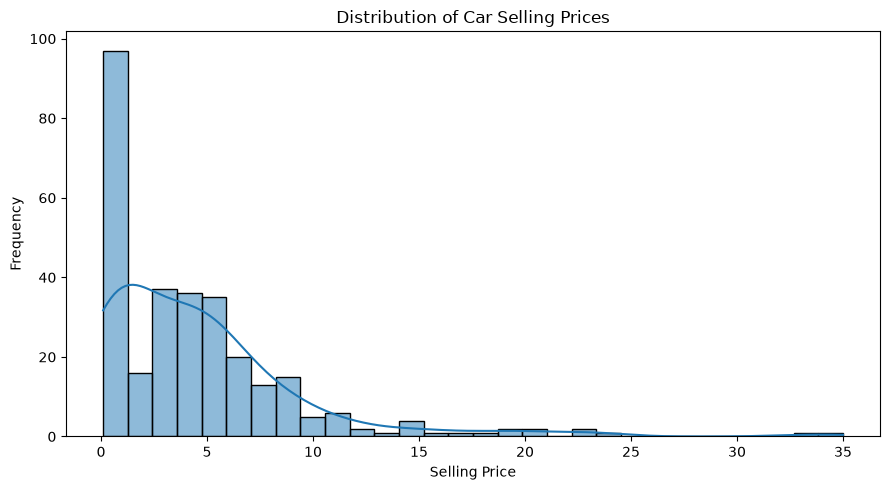

In [15]:
import matplotlib.pyplot as plt

# Plot the distribution of selling prices
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="Selling_Price", bins=30, kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

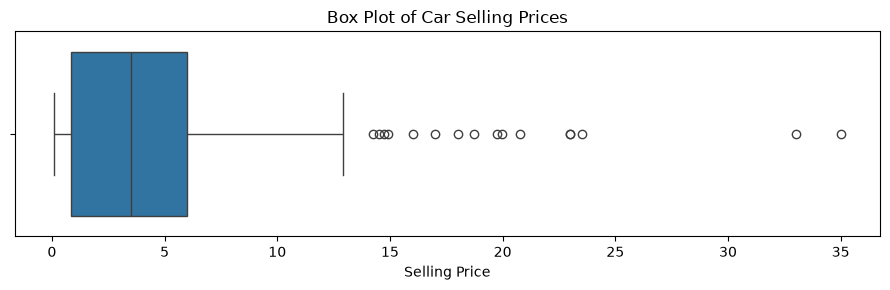

In [16]:
# Examine the spread and potential extreme values
plt.figure(figsize=(9, 3))

sns.boxplot(data=df, x="Selling_Price")

plt.title("Box Plot of Car Selling Prices")
plt.xlabel("Selling Price")
plt.tight_layout()
plt.show()

**Findings:** The distribution of `Selling_Price` is strongly right-skewed, with most observations concentrated at lower values and a long tail extending toward higher prices. The mean selling price (4.59) exceeds the median (3.51), supporting this observation. The box plot identifies several potential upper-end outliers, including observations with selling prices substantially above the upper whisker. These values may represent genuine differences among cars and will not be removed without further justification. The skewed distribution will be considered when evaluating regression model performance.

### 4.4 Distribution of Numerical Features

The distributions of `Year`, `Present_Price`, `Driven_kms`, and `Owner` will be visualized to better understand the numerical characteristics of the dataset.

These visualizations can reveal skewness, concentration around particular values, and observations that deserve closer inspection. The features will be interpreted according to their meanings rather than treating every numerical column as a continuous measurement.

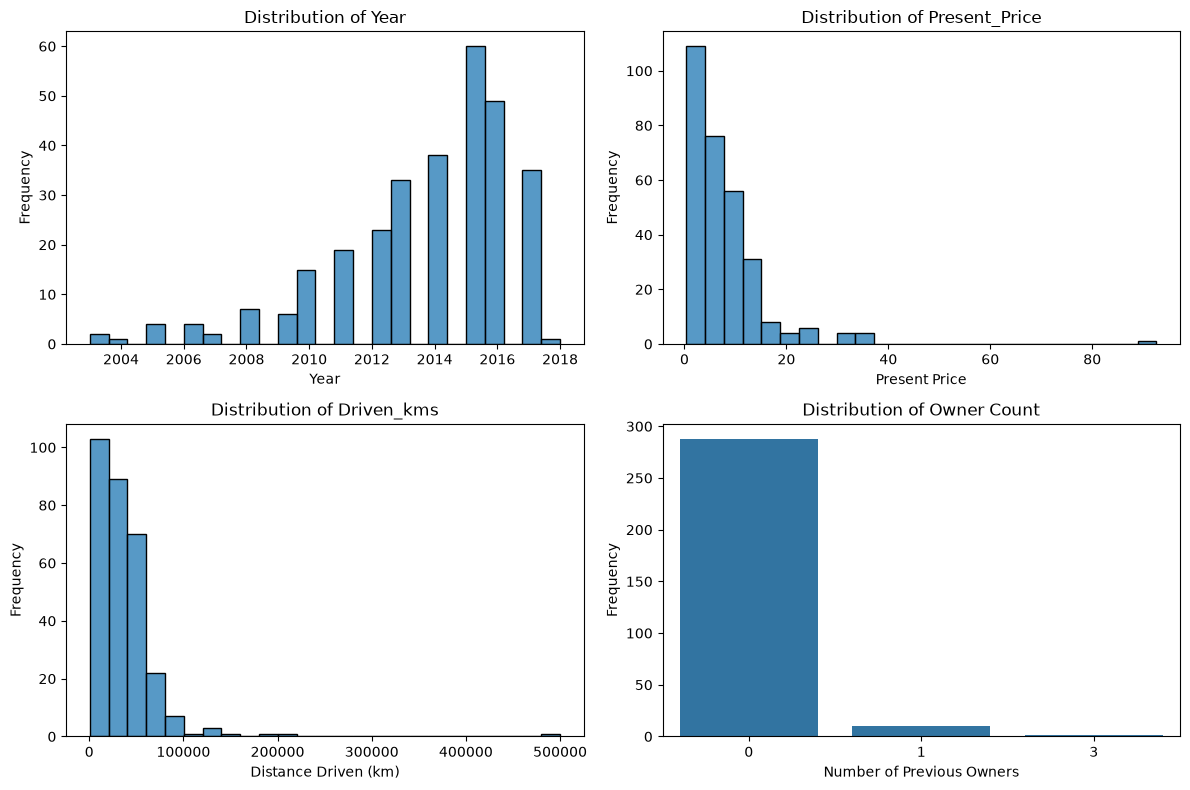

In [17]:
# Visualize the distributions of numerical features
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Manufacturing year
sns.histplot(data=df, x="Year", bins=25, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Year")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Frequency")

# Present price
sns.histplot(
    data=df, x="Present_Price", bins=25, ax=axes[0, 1]
)
axes[0, 1].set_title("Distribution of Present_Price")
axes[0, 1].set_xlabel("Present Price")
axes[0, 1].set_ylabel("Frequency")

# Distance driven
sns.histplot(
    data=df, x="Driven_kms", bins=25, ax=axes[1, 0]
)
axes[1, 0].set_title("Distribution of Driven_kms")
axes[1, 0].set_xlabel("Distance Driven (km)")
axes[1, 0].set_ylabel("Frequency")

# Owner count: use a count plot for discrete values
sns.countplot(data=df, x="Owner", ax=axes[1, 1])
axes[1, 1].set_title("Distribution of Owner Count")
axes[1, 1].set_xlabel("Number of Previous Owners")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Findings:** The manufacturing years are concentrated in the more recent part of the observed range, particularly around 2013–2017. `Present_Price` and `Driven_kms` exhibit strongly right-skewed distributions, with most observations concentrated at lower values and a small number extending to substantially higher values. The maximum present price of 92.6 and maximum distance driven of 500,000 warrant further contextual consideration but are not automatically treated as errors. The `Owner` feature is highly concentrated at zero, with relatively few nonzero observations. Since owner count is discrete, a count plot provides a clearer representation of its frequency distribution than a histogram.

### 4.5 Distribution of Categorical Features

Categorical features describe characteristics such as fuel type, selling type, and transmission type.

Count plots will be used to compare the frequency of each category. This helps identify dominant and less common categories, which is important when deciding how to encode categorical features for regression models.

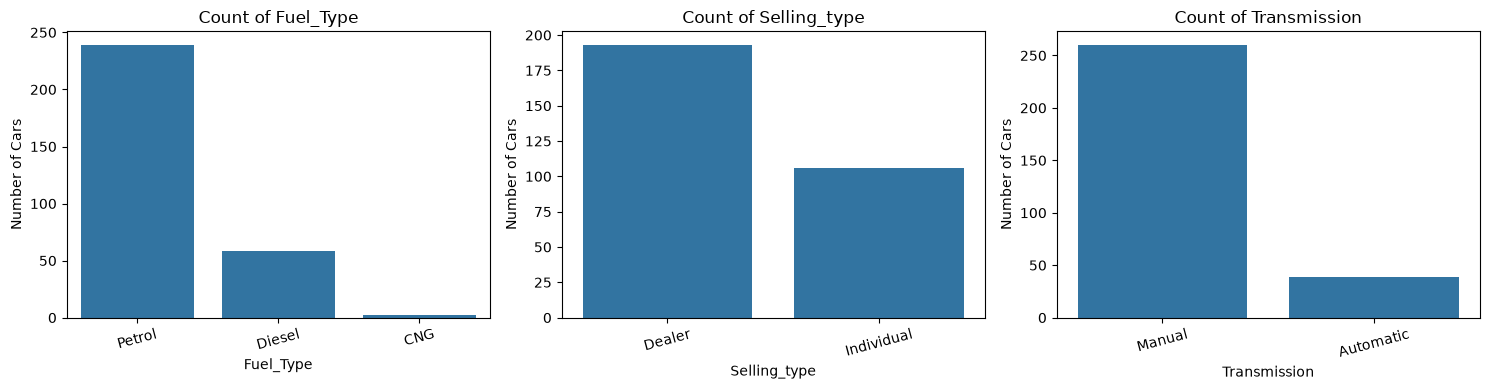

In [18]:
# Visualize the categorical feature distributions
categorical_features = [
    "Fuel_Type",
    "Selling_type",
    "Transmission"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for feature, ax in zip(categorical_features, axes):
    sns.countplot(data=df, x=feature, ax=ax)
    ax.set_title(f"Count of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Cars")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

**Findings:** The categorical features have different levels of class imbalance. Petrol is the dominant fuel type, representing approximately 79.9% of the cleaned dataset, while CNG accounts for only 0.7% with two observations. Dealer sales represent approximately 64.5% of records, and manual transmission accounts for approximately 87.0%. The rare CNG category and the predominance of manual transmission should be considered during model preprocessing and interpretation. These imbalances do not, by themselves, justify removing observations or categories.

### 4.6 Relationship Between Selling Price and Categorical Features

Box plots will be used to compare selling prices across the categories of `Fuel_Type`, `Selling_type`, and `Transmission`.

These plots show differences in the median selling prices and the spread of prices within each group. The results may reveal potentially useful patterns, although differences between groups do not by themselves establish causation.

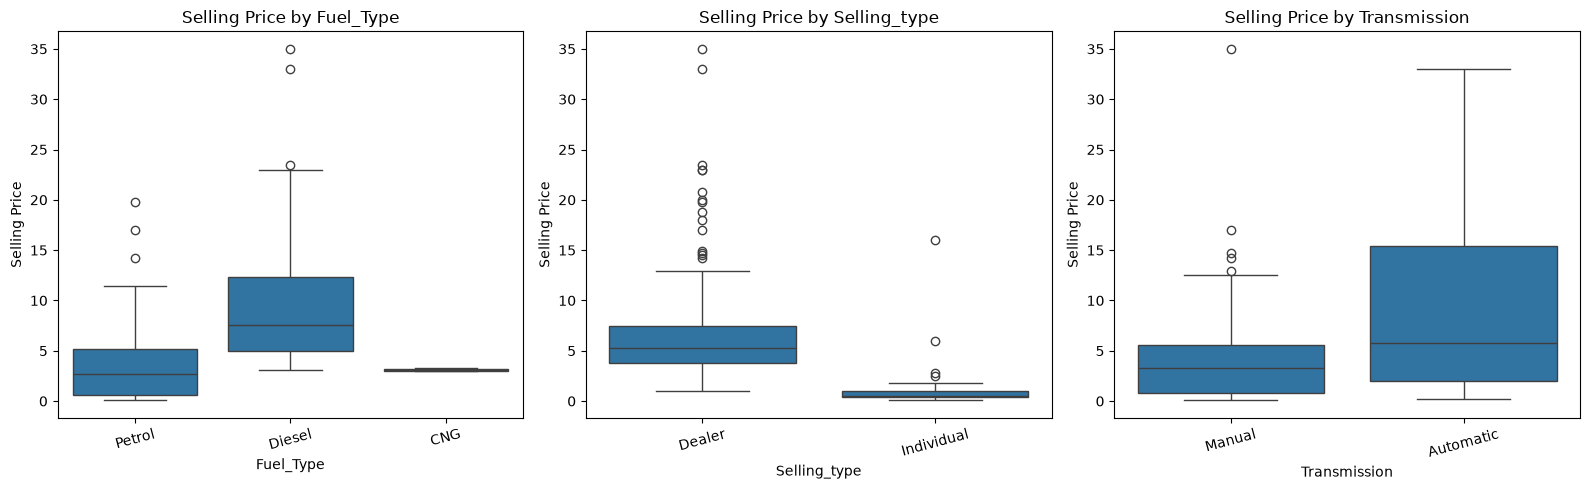

In [19]:
# Compare selling prices across categorical features
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for feature, ax in zip(categorical_features, axes):
    sns.boxplot(data=df, x=feature, y="Selling_Price", ax=ax)
    ax.set_title(f"Selling Price by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Selling Price")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

**Findings:** The box plots reveal differences in selling-price distributions across the categorical features. Diesel cars have a higher median selling price than petrol cars, while dealer sales have a higher median than individual sales. Automatic cars also show a higher median and a wider spread of selling prices than manual cars. The CNG category contains only two observations, limiting the conclusions that can be drawn for this group. Several categories contain potential upper-end outliers, consistent with the right-skewed target distribution observed in Section 4.3. These comparisons show associations rather than causal relationships, as other vehicle characteristics may contribute to the observed differences.

### 4.7 Relationship Between Selling Price and Numerical Features

Scatter plots will be used to investigate the relationships between `Selling_Price` and three numerical features: `Present_Price`, `Year`, and `Driven_kms`.

These visualizations can help identify positive or negative trends, nonlinear patterns, and observations that differ substantially from the general pattern. The results will help guide feature selection and model development.

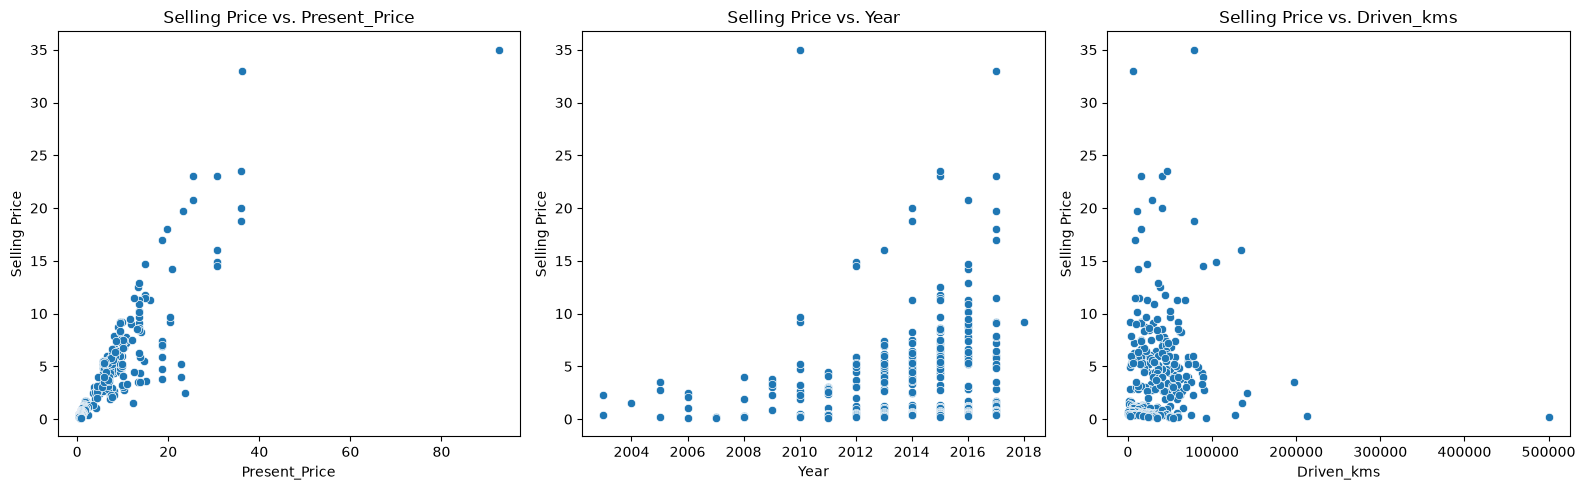

In [20]:
# Examine selling price against selected numerical features
numerical_predictors = [
    "Present_Price",
    "Year",
    "Driven_kms"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for feature, ax in zip(numerical_predictors, axes):
    sns.scatterplot(
        data=df,
        x=feature,
        y="Selling_Price",
        ax=ax
    )
    ax.set_title(f"Selling Price vs. {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Selling Price")

plt.tight_layout()
plt.show()

**Findings:** The scatter plots reveal different relationships between the numerical features and `Selling_Price`. `Present_Price` shows a strong positive association with selling price, making it a promising predictor. `Year` also shows a general tendency for more recent cars to have higher selling prices, although considerable variation remains within individual years. The relationship between `Driven_kms` and selling price is less clear, with substantial variation at lower mileage levels and a few extremely high-mileage observations. These patterns support considering all three features for regression modeling, while recognizing that visual associations do not establish causation or quantify predictive performance.

### 4.8 Correlation Analysis

A correlation matrix will be calculated to examine the linear relationships between numerical features.

The correlation coefficient ranges from -1 to +1. Values closer to +1 indicate a stronger positive linear relationship, values closer to -1 indicate a stronger negative linear relationship, and values near 0 indicate a weaker linear relationship.

Correlation does not establish causation, and a weak correlation does not necessarily mean that a feature is unhelpful for a nonlinear model.

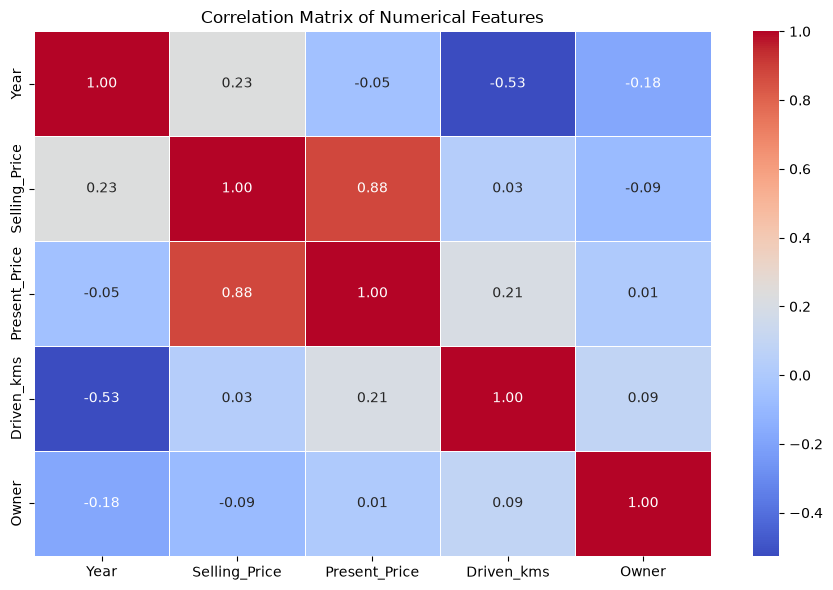

In [21]:
# Calculate correlations among numerical columns
correlation_matrix = df.select_dtypes(include="number").corr()

# Visualize the correlation matrix
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

**Findings:** The correlation analysis identifies a strong positive linear relationship between `Present_Price` and `Selling_Price` (r = 0.88), supporting the pattern observed in the scatter plot. `Year` has a weak positive correlation with selling price (r = 0.23), while `Driven_kms` (r = 0.03) and `Owner` (r = -0.09) have very weak linear correlations with the target. A moderate negative correlation exists between `Year` and `Driven_kms` (r = -0.53). These results help characterize linear relationships among the numerical features but do not establish causation or rule out nonlinear predictive relationships. The categorical features are not included in this correlation matrix because they are stored as non-numeric variables.

### 4.9 EDA Findings

The exploratory data analysis revealed several important characteristics of the cleaned car dataset.

- **Dataset quality:** The cleaned dataset contains 299 rows and 9 columns. No missing values were found, and two duplicate row occurrences were removed during data cleaning.
- **Target distribution:** `Selling_Price` is strongly right-skewed, with most observations concentrated at lower values and several potential upper-end outliers.
- **Numerical features:** `Present_Price` and `Driven_kms` also exhibit strongly right-skewed distributions. `Year` is concentrated toward more recent manufacturing years, while `Owner` is heavily concentrated at zero.
- **Categorical features:** Petrol is the dominant fuel type, manual transmission is substantially more common than automatic transmission, and dealer sales outnumber individual sales. CNG is particularly rare, with only two observations.
- **Relationships with selling price:** Box plots show higher median selling prices for diesel cars, dealer sales, and automatic cars compared with their respective alternatives. These are observed group differences and do not establish causation.
- **Numerical associations:** `Present_Price` has a strong positive linear correlation with `Selling_Price` (r = 0.88). `Year` has a weak positive correlation (r = 0.23), while `Driven_kms` (r = 0.03) and `Owner` (r = -0.09) have very weak linear correlations with the target.
- **Potential outliers:** Several observations have unusually high selling prices, present prices, or distances driven. These observations have been retained because their appearance alone does not establish that they are errors.

Overall, the EDA identifies `Present_Price` as a promising predictor and suggests that the categorical features and other numerical variables may provide additional predictive information. The strength of their contribution must be assessed through regression modeling and evaluation on held-out data. The observed associations do not establish causal relationships, and the rare CNG category warrants particular caution when interpreting model behavior.

## 5. Feature Preparation and Preprocessing

Feature preparation is an important stage in a machine learning workflow. The dataset must be organized into input features and a target variable before regression models can be trained.

In this project, `Selling_Price` is the target variable because the objective is to predict the selling price of a car. The remaining columns describe vehicle characteristics and selling conditions that may help explain price differences.

The features will be examined before preprocessing decisions are finalized. Categorical variables must be represented in a format suitable for the selected regression algorithms, and the data must be divided into training and testing sets to evaluate performance on unseen observations.

### 5.1 Defining the Features and Target

The target variable is separated from the input features to establish the prediction task explicitly. The target contains the selling prices, while the input features contain the information available to predict those prices.

The dataset dimensions and selected columns will be checked to ensure that the target and features have been separated correctly.

In [22]:
# Define the target variable
target = "Selling_Price"

# Separate input features and target
X = df.drop(columns=[target])
y = df[target]

# Inspect the feature and target dimensions
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:", target)

Feature matrix shape: (299, 8)
Target vector shape: (299,)

Input features:
['Car_Name', 'Year', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Target variable: Selling_Price


### 5.2 Inspecting Feature Types

Regression algorithms generally require numerical input, so categorical features must be converted into an appropriate numerical representation.

The input features include numerical measurements such as `Year`, `Present_Price`, and `Driven_kms`, along with categorical attributes such as `Fuel_Type`, `Selling_type`, and `Transmission`. `Car_Name` is also categorical and contains many distinct values.

The feature data types and category counts will be examined before choosing an encoding strategy. This helps avoid unnecessary complexity and supports a consistent preprocessing workflow.

In [23]:
# Inspect feature data types
print("Feature data types:")
display(X.dtypes)

# Identify categorical and numerical features
categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include="number"
).columns.tolist()

print("\nNumerical features:", numerical_features)
print("Categorical features:", categorical_features)

print("\nNumber of unique values in categorical features:")
display(X[categorical_features].nunique().to_frame(name="Unique Values"))

Feature data types:


Car_Name             str
Year               int64
Present_Price    float64
Driven_kms         int64
Fuel_Type            str
Selling_type         str
Transmission         str
Owner              int64
dtype: object


Numerical features: ['Year', 'Present_Price', 'Driven_kms', 'Owner']
Categorical features: ['Car_Name', 'Fuel_Type', 'Selling_type', 'Transmission']

Number of unique values in categorical features:


,Unique Values
Car_Name,98
Fuel_Type,3
Selling_type,2
Transmission,2


### 5.3 Selecting Features for Modeling

The initial feature inspection identified `Car_Name` as a high-cardinality categorical feature, with 98 unique values across 299 observations. Encoding every car name would substantially increase the number of input columns and could make the model more susceptible to overfitting.

For the initial modeling workflow, `Car_Name` will therefore be excluded from the input features. The remaining numerical features and the categorical features with relatively few distinct values will be retained.

This is a modeling decision rather than a data-cleaning operation: the original cleaned DataFrame remains unchanged. The effect of including or excluding `Car_Name` can be evaluated in a later experiment.

In [24]:
# Exclude the high-cardinality Car_Name feature
features_to_exclude = ["Car_Name"]

X_model = X.drop(columns=features_to_exclude)

# Re-identify numerical and categorical features
categorical_features = X_model.select_dtypes(
    include=["object", "str"]
).columns.tolist()

numerical_features = X_model.select_dtypes(
    include="number"
).columns.tolist()

# Verify the selected features
print("Model feature matrix shape:", X_model.shape)

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nRemaining columns:")
print(X_model.columns.tolist())

Model feature matrix shape: (299, 7)

Numerical features:
['Year', 'Present_Price', 'Driven_kms', 'Owner']

Categorical features:
['Fuel_Type', 'Selling_type', 'Transmission']

Remaining columns:
['Year', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']


### 5.4 Splitting the Dataset

Before training a regression model, the dataset is divided into training and testing subsets. The training set is used to fit the model, while the testing set is reserved for evaluating its performance on unseen observations.

In this project, 80% of the observations will be allocated to training and 20% to testing. A fixed `random_state` is used to make the split reproducible, allowing the same observations to be assigned to each subset when the code is run again.

The split is performed before fitting any preprocessing transformations. This helps prevent information from the test set from influencing the training process.

In [25]:
from sklearn.model_selection import train_test_split

# Split the features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=0.2,
    random_state=42
)

# Check the dimensions of each subset
print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)

print("\nTraining target vector:", y_train.shape)
print("Testing target vector:", y_test.shape)

Training feature matrix: (239, 7)
Testing feature matrix: (60, 7)

Training target vector: (239,)
Testing target vector: (60,)


### 5.5 Building the Preprocessing Pipeline

The selected input features contain both numerical and categorical variables. Most regression algorithms require these features to be represented numerically in a suitable format.

Two preprocessing techniques will be used:

- **Standardization:** Numerical features will be transformed using `StandardScaler`. This subtracts the training-set mean and divides by the training-set standard deviation.
- **One-hot encoding:** Categorical features will be converted into binary indicator columns using `OneHotEncoder`.

A `ColumnTransformer` will apply the appropriate transformation to each feature group, while a scikit-learn `Pipeline` will keep preprocessing steps organized and consistent with model training.

The encoder will use `handle_unknown="ignore"` so that an unfamiliar category in the test set does not cause a transformation error. The preprocessing pipeline will be fitted on the training data only.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Define preprocessing for numerical features
numerical_transformer = StandardScaler()

# Define preprocessing for categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Apply the appropriate transformation to each feature group
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Create the preprocessing pipeline
preprocessing_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


### 5.6 Applying the Preprocessing Transformations

The preprocessing pipeline is now applied to the training and testing feature sets. First, the pipeline is fitted on the training data so that the numerical scaling parameters and categorical encoding categories are learned from training observations only.

The fitted pipeline then transforms both the training and testing data using the same learned parameters and encoding structure. This ensures that the test set remains independent of the preprocessing fitting process.

The transformed feature matrices will be inspected to verify their dimensions and confirm that the preprocessing steps have produced numerical model inputs.

In [27]:
# Fit the preprocessing pipeline on the training data
X_train_processed = preprocessing_pipeline.fit_transform(X_train)

# Transform the testing data using the fitted pipeline
X_test_processed = preprocessing_pipeline.transform(X_test)

# Inspect the transformed data dimensions
print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

# Check the resulting data type
print("\nProcessed training data type:", type(X_train_processed))
print("Processed testing data type:", type(X_test_processed))

Processed training data shape: (239, 11)
Processed testing data shape: (60, 11)

Processed training data type: <class 'numpy.ndarray'>
Processed testing data type: <class 'numpy.ndarray'>


### 5.7 Summary of Feature Preparation

The feature preparation stage is complete. The target variable, `Selling_Price`, was separated from the input features, and the high-cardinality `Car_Name` feature was excluded from the initial modeling experiment.

The remaining seven input features were divided into numerical and categorical groups. The dataset was split into training and testing subsets, with 239 observations for training and 60 for testing.

A preprocessing pipeline was configured to standardize numerical features and one-hot encode categorical features. After transformation, the training and testing matrices each contained 11 numerical input columns.

These prepared features are ready for regression modeling. The next stage will train a baseline model and evaluate its predictive performance on the held-out test set.

## 6. Model Training and Evaluation

With data preparation complete, the next step is to train regression models to predict `Selling_Price`. Model performance will be evaluated using the held-out test set to estimate how well each model generalizes to unseen observations.

Linear Regression will be used as the baseline model. Its performance will provide a reference point for comparison with other regression algorithms.

The preprocessing steps will be combined with each estimator in a single scikit-learn pipeline. This keeps the workflow consistent and helps prevent data leakage by ensuring that preprocessing is fitted using the training data only.

Model performance will be assessed using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the coefficient of determination (\(R^2\)). These metrics provide complementary views of prediction error and model fit.

### 6.1 Establishing a Baseline with Linear Regression

Linear Regression is a supervised learning algorithm that models the relationship between input features and a numerical target. It estimates coefficients for the input features to minimize the sum of squared differences between actual and predicted target values.

In this project, the model will use the selected vehicle features to predict `Selling_Price`. Numerical features will be standardized, and categorical features will be one-hot encoded within the pipeline before the model is fitted.

Linear Regression is a useful starting point because it is relatively simple to interpret and provides a baseline against which more complex models can be compared. However, it assumes an additive linear relationship between the transformed features and the target, so it may not capture every pattern in car prices.

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# Combine preprocessing and Linear Regression into one pipeline
linear_regression_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

# Train the model using only the training data
linear_regression_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


### 6.2 Generating Predictions and Evaluating the Baseline Model

After training the Linear Regression model, predictions are generated for the held-out testing set. These predictions are compared with the actual selling prices using regression evaluation metrics.

Four metrics will be used:

- **Mean Absolute Error (MAE):** The average absolute difference between actual and predicted prices. Lower values indicate smaller errors.
- **Mean Squared Error (MSE):** The average squared prediction error. Larger errors receive a greater penalty because the errors are squared.
- **Root Mean Squared Error (RMSE):** The square root of MSE. It expresses prediction error in the same units as the target variable.
- **R² Score:** Measures how well the model performs relative to predicting the mean target value of the test set. A score closer to 1 generally indicates better performance; a negative score means the model performs worse than that mean-based reference on the test set.

These metrics will establish a baseline for comparing subsequent regression models. Their values should be interpreted together rather than relying on a single metric.

In [29]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Generate predictions for the held-out test set
y_pred = linear_regression_model.predict(X_test)

# Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display the results
print("Linear Regression - Test Set Performance")
print("-" * 42)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE):  {mse:.4f}")
print(f"Root Mean Squared Error:   {rmse:.4f}")
print(f"R² Score:                  {r2:.4f}")

Linear Regression - Test Set Performance
------------------------------------------
Mean Absolute Error (MAE): 1.4725
Mean Squared Error (MSE):  6.3731
Root Mean Squared Error:   2.5245
R² Score:                  0.7527


### 6.3 Baseline Model Findings

The Linear Regression model was trained using the prepared training dataset and evaluated on 60 held-out test observations.

The model achieved a Mean Absolute Error (MAE) of 1.4725, a Mean Squared Error (MSE) of 6.3731, a Root Mean Squared Error (RMSE) of 2.5245, and an R² score of 0.7527.

The R² result indicates that the model explains approximately 75.27% of the variation in selling prices in the test set relative to a mean-based prediction benchmark. The RMSE being higher than the MAE indicates that larger prediction errors have a noticeable influence on the squared-error metric.

These results establish the initial performance baseline. Further regression models will be evaluated using the same train/test split and evaluation metrics to determine whether they improve predictive performance. The baseline results alone are not sufficient to establish which model will perform best.

### 6.4 Visualizing Actual vs. Predicted Prices

Evaluation metrics summarize model performance numerically, but a plot of actual versus predicted selling prices provides an additional visual assessment.

In an ideal prediction, each predicted value equals its corresponding actual value. A reference line representing perfect predictions will therefore be included. Points close to this line indicate predictions close to the observed values, while points farther away represent larger prediction errors.

This visualization can help reveal systematic deviations and unusually large errors that may not be obvious from summary metrics alone.

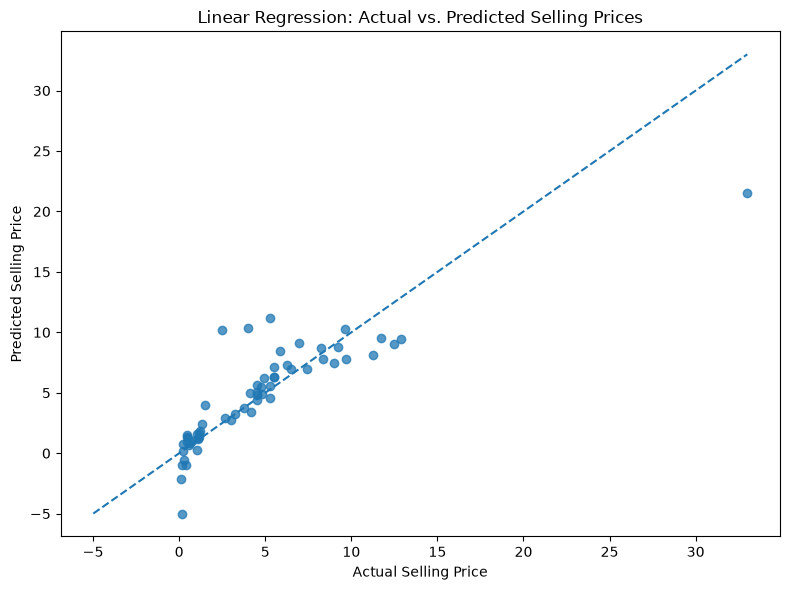

In [30]:
import matplotlib.pyplot as plt

# Plot actual versus predicted selling prices
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.75)

# Reference line for perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Linear Regression: Actual vs. Predicted Selling Prices")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.tight_layout()
plt.show()

### 6.5 Actual vs. Predicted Price Analysis

The actual-versus-predicted plot shows that many predictions are reasonably close to the reference line, particularly among lower-priced observations. However, several points deviate noticeably from the line, indicating substantial prediction errors for some vehicles.

The model tends to underestimate some of the higher selling prices, including an observation with an actual price of approximately 33 and a predicted price of approximately 21.5. Some other observations are overpredicted, demonstrating that the errors are not uniform across the dataset.

The plot also contains a negative predicted selling price. Since selling prices cannot be negative in practice, this highlights a limitation of unconstrained Linear Regression.

Overall, the visualization supports the numerical evaluation results: Linear Regression provides a useful baseline but does not capture every observed price pattern accurately. Additional regression models will be tested to determine whether predictive performance can be improved.

### 6.6 Residual Analysis

Residual analysis provides another way to evaluate the behavior of a regression model. A residual is calculated by subtracting the predicted selling price from the actual selling price.

Residuals will be plotted against predicted selling prices, with a horizontal reference line at zero. Residuals distributed around zero without a clear systematic pattern are generally desirable. Visible patterns or changes in residual spread may indicate that the model does not capture all relationships in the data or that prediction errors vary across price levels.

This analysis complements the evaluation metrics and actual-versus-predicted plot by helping identify potential patterns in the model's errors.

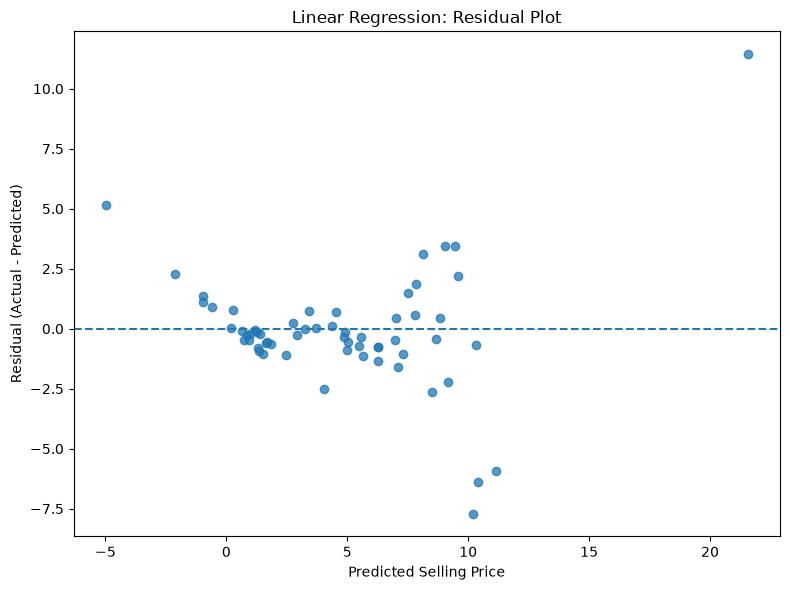

In [31]:
# Calculate residuals
residuals = y_test - y_pred

# Plot residuals against predicted prices
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.75)
plt.axhline(y=0, linestyle="--")

plt.title("Linear Regression: Residual Plot")
plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

### 6.7 Residual Analysis Findings

The residual plot shows that many observations have residuals relatively close to zero, particularly in the lower predicted-price range. However, several observations have substantial positive or negative residuals, indicating that the model makes large errors for some vehicles.

A large positive residual indicates underprediction, while a large negative residual indicates overprediction. The plot includes a substantial positive residual at a higher predicted price and several negative residuals around predicted prices of 10–11.

The spread of residuals also appears to vary across the range of predicted prices. This may indicate that prediction errors are not equally dispersed across all price levels, although the limited test-set size warrants caution.

Overall, the residual analysis reinforces the conclusion that Linear Regression provides a useful baseline but has limitations in predicting some vehicle prices. More flexible regression algorithms will be evaluated to determine whether they can improve performance.

### 6.8 Decision Tree Regression

#### 6.8.1 Understanding the model

Decision Tree Regression is a supervised learning algorithm that predicts numerical values by dividing the feature space into smaller regions based on feature conditions. Each final region produces a prediction based on the target values of the training observations within that region.

Unlike Linear Regression, a decision tree can capture nonlinear relationships and interactions between features without requiring a linear relationship between each feature and the target.

However, decision trees can overfit when they become too complex. A tree may fit the training observations closely but perform less accurately on unseen data. In this section, a Decision Tree Regressor will be trained using the same training and testing split as the baseline model. Its performance will then be compared with Linear Regression using the same evaluation metrics.

#### 6.8.2 Training the Decision Tree Regressor

In [32]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

# Create a pipeline with preprocessing and Decision Tree Regression
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(random_state=42))
    ]
)

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree Regression model trained successfully.")

Decision Tree Regression model trained successfully.


#### 6.8.3 Evaluating the Decision Tree Regressor

After training, the Decision Tree Regressor will generate predictions for the held-out test set. The predictions will be evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the R² score.

The same test observations and evaluation metrics used for Linear Regression will be used here. This allows the results to be compared directly and helps determine whether the decision tree provides better predictive performance on this particular split.

In [33]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Generate predictions on the test set
y_pred_tree = decision_tree_model.predict(X_test)

# Calculate evaluation metrics
tree_mae = mean_absolute_error(y_test, y_pred_tree)
tree_mse = mean_squared_error(y_test, y_pred_tree)
tree_rmse = np.sqrt(tree_mse)
tree_r2 = r2_score(y_test, y_pred_tree)

# Display results
print("Decision Tree Regression - Test Set Performance")
print("-" * 48)
print(f"Mean Absolute Error (MAE): {tree_mae:.4f}")
print(f"Mean Squared Error (MSE):  {tree_mse:.4f}")
print(f"Root Mean Squared Error:   {tree_rmse:.4f}")
print(f"R² Score:                  {tree_r2:.4f}")

Decision Tree Regression - Test Set Performance
------------------------------------------------
Mean Absolute Error (MAE): 1.1048
Mean Squared Error (MSE):  4.3921
Root Mean Squared Error:   2.0957
R² Score:                  0.8296


#### 6.8.4 Comparison with the Linear Regression Baseline

The Decision Tree Regressor outperformed the Linear Regression baseline across all four evaluation metrics on the held-out test set.

The Decision Tree achieved an MAE of 1.1048, an MSE of 4.3921, an RMSE of 2.0957, and an R² score of 0.8296. Compared with Linear Regression, its MAE and RMSE were lower, while its R² score was higher.

These results suggest that the Decision Tree captured patterns in the selected features that were not represented as effectively by the linear baseline. However, performance on a single train/test split does not establish that the Decision Tree will generalize better in every sample. Further model comparisons and validation are needed before selecting a final model.

### 6.9 Visualizing Decision Tree Predictions

An actual-versus-predicted plot will be used to examine the Decision Tree Regressor's predictions. The horizontal axis represents actual selling prices, while the vertical axis represents predicted selling prices.

The diagonal reference line represents perfect predictions. Points closer to this line indicate smaller prediction errors, while points farther from it indicate larger errors.

The resulting plot can be compared with the Linear Regression visualization to assess whether the Decision Tree produces predictions that are more closely aligned with the observed selling prices.

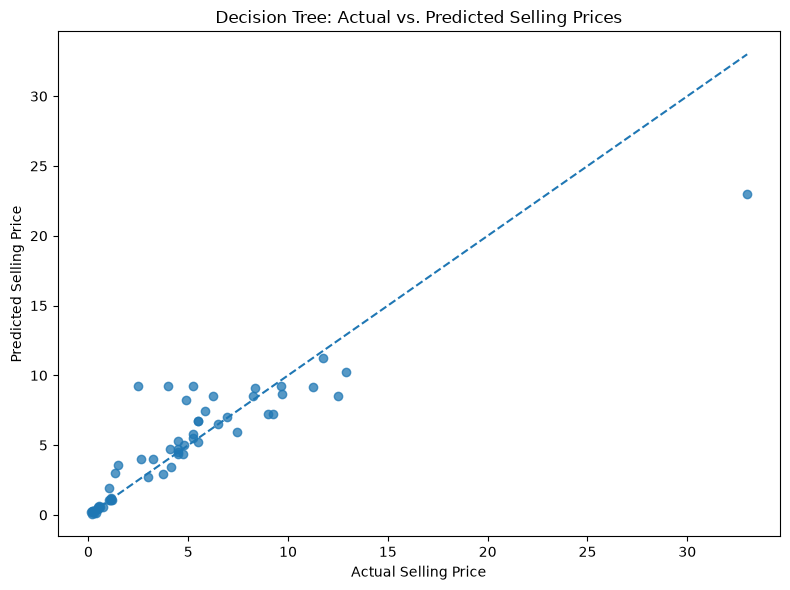

In [34]:
# Plot actual versus predicted prices for the Decision Tree
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_tree, alpha=0.75)

# Reference line for perfect predictions
min_price = min(y_test.min(), y_pred_tree.min())
max_price = max(y_test.max(), y_pred_tree.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Decision Tree: Actual vs. Predicted Selling Prices")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.tight_layout()
plt.show()

### 6.10 Decision Tree Prediction Analysis

The actual-versus-predicted plot shows that many Decision Tree predictions are relatively close to the ideal reference line, particularly among lower-priced observations. However, some predictions deviate noticeably from the line, indicating that substantial errors remain for certain vehicles.

The model underpredicts some higher selling prices, including an observation with an actual price of approximately 33 and a predicted price of approximately 23. Both overprediction and underprediction are visible across the test observations.

Several predictions are clustered around similar values. This behavior is characteristic of decision trees, which produce constant predictions within their terminal leaves.

Overall, the visualization is consistent with the Decision Tree's improved test-set metrics compared with Linear Regression, while also showing that the model does not predict all price ranges equally accurately. Further evaluation is needed before selecting a final model.

### 6.11 Decision Tree Residual Analysis

Residual analysis is used to examine the differences between actual and predicted selling prices. Residuals are calculated by subtracting predicted values from actual values.

A residual plot will be created with predicted selling prices on the horizontal axis and residuals on the vertical axis. A horizontal reference line at zero will help distinguish underpredictions from overpredictions.

This visualization will help identify large errors and assess whether the Decision Tree's residuals show patterns across the range of predicted prices.

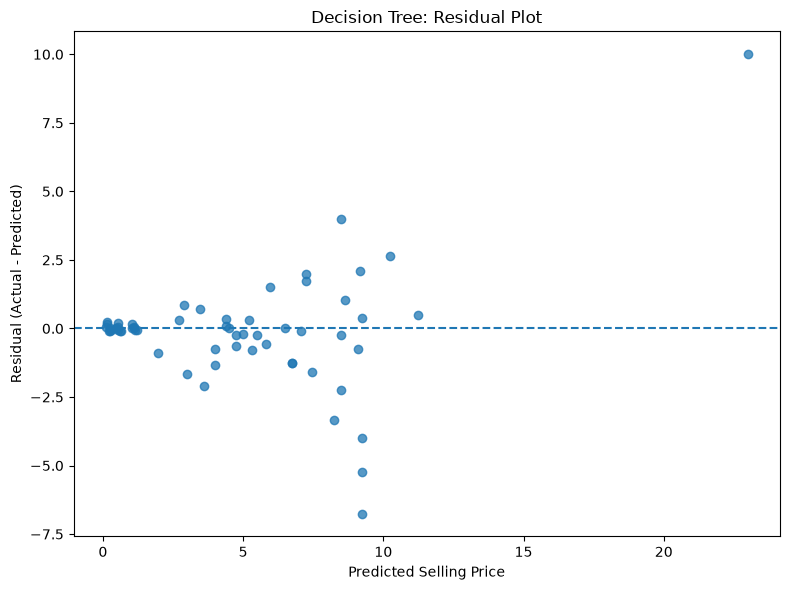

In [35]:
# Calculate residuals for the Decision Tree
residuals_tree = y_test - y_pred_tree

# Plot Decision Tree residuals
plt.figure(figsize=(8, 6))

plt.scatter(y_pred_tree, residuals_tree, alpha=0.75)
plt.axhline(y=0, linestyle="--")

plt.title("Decision Tree: Residual Plot")
plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

### 6.12 Decision Tree Residual Analysis Findings

The Decision Tree residual plot shows that many observations in the lower predicted-price range have residuals close to zero. However, the residuals become more dispersed at higher predicted prices, and several observations have substantial prediction errors.

Several large negative residuals occur around predicted prices of 8–9, indicating that the model overpredicted the corresponding selling prices. A large positive residual is also visible at a predicted price of approximately 23, indicating substantial underprediction for that observation.

The variation in residual spread suggests that the model's prediction errors differ across price levels. Although the Decision Tree outperformed Linear Regression on the four test-set metrics, the residual plot shows that some difficult-to-predict observations remain.

These findings reinforce the need to compare additional models and validate their performance before selecting a final estimator.

### 6.13 Comparing Regression Models

The Linear Regression and Decision Tree Regressor models have been evaluated using the same held-out test set and four regression metrics. Comparing their results provides an initial assessment of their relative predictive performance.

Lower MAE, MSE, and RMSE values indicate smaller prediction errors, while a higher R² score generally indicates better performance relative to a mean-based prediction benchmark.

The comparison will be expanded as additional regression models are trained. Model selection will consider test-set performance and the risk of overfitting rather than relying on a single metric alone.

In [36]:
import pandas as pd

# Compare the evaluated models
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree Regression"
    ],
    "MAE": [
        mae,
        tree_mae
    ],
    "MSE": [
        mse,
        tree_mse
    ],
    "RMSE": [
        rmse,
        tree_rmse
    ],
    "R2 Score": [
        r2,
        tree_r2
    ]
})

display(model_comparison.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.4725,6.3731,2.5245,0.7527
1,Decision Tree Regression,1.1048,4.3921,2.0957,0.8296


### 6.14 Model Comparison Findings

The initial comparison shows that Decision Tree Regression outperformed Linear Regression across all four evaluation metrics on the held-out test set.

The Decision Tree reduced MAE from 1.4725 to 1.1048 and RMSE from 2.5245 to 2.0957. Its R² score increased from 0.7527 to 0.8296, indicating better performance relative to the test-set mean baseline.

These results suggest that the Decision Tree captures the relationships in the selected features more effectively than the linear baseline on this test split. However, a single train/test split provides limited evidence about performance stability, and the default Decision Tree may be sensitive to the training data.

The Decision Tree will remain the leading model in the current comparison, but further experiments and validation are needed before choosing the final model.

### 6.15 Random Forest Regression

Random Forest Regression is an ensemble learning algorithm that trains multiple decision trees using randomized training samples and feature selection. The predictions from the individual trees are combined to produce the final prediction.

By averaging predictions across multiple trees, a Random Forest can reduce the variance associated with an individual decision tree and may generalize more reliably to unseen observations.

In this project, Random Forest Regression will be evaluated using the same training and testing split and the same four regression metrics. Its performance will be compared with the existing Linear Regression and Decision Tree models.

#### 6.15.1 Training the Random Forest Regressor

In [37]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Create a pipeline with preprocessing and Random Forest Regression
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]
)

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest Regression model trained successfully.")

Random Forest Regression model trained successfully.


#### 6.15.2 Evaluating the Random Forest Regressor

The trained Random Forest Regressor will generate predictions for the held-out test set. MAE, MSE, RMSE, and R² will be calculated to evaluate its predictive performance.

The results will be compared with those of Linear Regression and Decision Tree Regression. Using the same test observations and metrics provides a consistent initial comparison of all three algorithms.

In [38]:
# Generate predictions on the test set
y_pred_rf = random_forest_model.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, y_pred_rf)

# Display results
print("Random Forest Regression - Test Set Performance")
print("-" * 49)
print(f"Mean Absolute Error (MAE): {rf_mae:.4f}")
print(f"Mean Squared Error (MSE):  {rf_mse:.4f}")
print(f"Root Mean Squared Error:   {rf_rmse:.4f}")
print(f"R² Score:                  {rf_r2:.4f}")

Random Forest Regression - Test Set Performance
-------------------------------------------------
Mean Absolute Error (MAE): 1.5448
Mean Squared Error (MSE):  14.3366
Root Mean Squared Error:   3.7864
R² Score:                  0.4437


#### 6.15.3 Random Forest Evaluation Findings

The Random Forest Regressor achieved an MAE of 1.5448, an MSE of 14.3366, an RMSE of 3.7864, and an R² score of 0.4437 on the held-out test set.

Compared with Linear Regression and Decision Tree Regression, Random Forest produced higher MAE, MSE, and RMSE values and a lower R² score. Therefore, its predictive performance was weaker than both models on the current train/test split.

Although Random Forest combines multiple decision trees, this ensemble did not improve performance under the initial configuration. Further investigation or hyperparameter tuning may be useful, but the current results do not justify selecting it as the best-performing model.

The Decision Tree remains the leading model among the three evaluated algorithms.

### 6.16 Model Comparison After Three Algorithms

In [39]:
# Compare all three evaluated models
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        mae,
        tree_mae,
        rf_mae
    ],
    "MSE": [
        mse,
        tree_mse,
        rf_mse
    ],
    "RMSE": [
        rmse,
        tree_rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        tree_r2,
        rf_r2
    ]
})

display(model_comparison.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.4725,6.3731,2.5245,0.7527
1,Decision Tree Regression,1.1048,4.3921,2.0957,0.8296
2,Random Forest Regression,1.5448,14.3366,3.7864,0.4437


### 6.17 Gradient Boosting Regression

Gradient Boosting Regression is an ensemble learning technique that builds decision trees sequentially. Each new tree is trained to improve the current ensemble by reducing the remaining prediction errors according to a loss function.

Unlike Random Forest Regression, which combines predictions from independently constructed trees, Gradient Boosting learns successive corrections to the ensemble's predictions. It can model nonlinear relationships but may overfit if its complexity is not controlled.

In this project, Gradient Boosting Regression will be evaluated using the same training and testing split and the same regression metrics as the previous models. Its results will be compared with the existing models to determine whether it improves prediction performance.

#### 6.17.1 Training the Gradient Boosting Regressor

In [40]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline

# Create a pipeline with preprocessing and Gradient Boosting
gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ]
)

# Train the model
gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting Regression model trained successfully.")

Gradient Boosting Regression model trained successfully.


#### 6.17.2 Evaluating the Gradient Boosting Regressor

After training, the Gradient Boosting Regressor will generate predictions for the held-out test set. Its performance will be assessed using MAE, MSE, RMSE, and R².

The same test observations and evaluation metrics will be used for all models, providing a consistent initial comparison. The results will help determine whether the sequential boosting approach performs better than the linear, single-tree, and Random Forest models on this test split.

In [41]:
# Generate predictions on the test set
y_pred_gb = gradient_boosting_model.predict(X_test)

# Calculate evaluation metrics
gb_mae = mean_absolute_error(y_test, y_pred_gb)
gb_mse = mean_squared_error(y_test, y_pred_gb)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test, y_pred_gb)

# Display results
print("Gradient Boosting Regression - Test Set Performance")
print("-" * 53)
print(f"Mean Absolute Error (MAE): {gb_mae:.4f}")
print(f"Mean Squared Error (MSE):  {gb_mse:.4f}")
print(f"Root Mean Squared Error:   {gb_rmse:.4f}")
print(f"R² Score:                  {gb_r2:.4f}")

Gradient Boosting Regression - Test Set Performance
-----------------------------------------------------
Mean Absolute Error (MAE): 1.1473
Mean Squared Error (MSE):  6.4080
Root Mean Squared Error:   2.5314
R² Score:                  0.7514


#### 6.17.3 Gradient Boosting Evaluation Findings

The Gradient Boosting Regressor achieved an MAE of 1.1473, an MSE of 6.4080, an RMSE of 2.5314, and an R² score of 0.7514 on the held-out test set.

Compared with Linear Regression, Gradient Boosting achieved a lower MAE but slightly higher MSE and RMSE, along with a slightly lower R² score. Its performance was therefore mixed relative to the linear baseline.

The model did not outperform Decision Tree Regression, which achieved lower errors and a higher R² score on the same test observations. These findings show that the initial Gradient Boosting configuration did not produce the best predictive performance in this experiment.

Further validation and hyperparameter tuning may help determine whether different settings improve its performance.

In [42]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree Regression",
        "Random Forest Regression",
        "Gradient Boosting Regression"
    ],
    "MAE": [
        mae, tree_mae, rf_mae, gb_mae
    ],
    "MSE": [
        mse, tree_mse, rf_mse, gb_mse
    ],
    "RMSE": [
        rmse, tree_rmse, rf_rmse, gb_rmse
    ],
    "R2 Score": [
        r2, tree_r2, rf_r2, gb_r2
    ]
})

display(
    model_comparison
    .sort_values(by="RMSE")
    .round(4)
    .reset_index(drop=True)
)

,Model,MAE,MSE,RMSE,R2 Score
0,Decision Tree Regression,1.1048,4.3921,2.0957,0.8296
1,Linear Regression,1.4725,6.3731,2.5245,0.7527
2,Gradient Boosting Regression,1.1473,6.4080,2.5314,0.7514
3,Random Forest Regression,1.5448,14.3366,3.7864,0.4437


### 6.18 Cross-Validation for Model Validation

A single train/test split provides one estimate of model performance, but the result can depend on which observations are assigned to each subset. Cross-validation provides additional evidence about model performance by evaluating it across multiple training and validation splits.

In this project, five-fold cross-validation was performed using the training data only. The test set was kept separate during cross-validation, but its results were also considered in the final model comparison.

The four regression models were evaluated using Root Mean Squared Error (RMSE). For each model, the mean and standard deviation of the cross-validation RMSE scores were examined. A lower mean RMSE indicates better average validation performance, while a lower standard deviation suggests more consistent performance across folds.

Each model's preprocessing and regression steps remained within a single pipeline so that transformations were fitted independently within each cross-validation fold.

#### 6.18.1 Performing 5-Fold Cross-Validation

In [43]:
from sklearn.model_selection import KFold, cross_val_score

# Define a reproducible five-fold cross-validation strategy
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Collect the models for comparison
models = {
    "Linear Regression": linear_regression_model,
    "Decision Tree Regression": decision_tree_model,
    "Random Forest Regression": random_forest_model,
    "Gradient Boosting Regression": gradient_boosting_model
}

# Evaluate each model using training data only
cv_results = []

for model_name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    # Convert negative RMSE scores into positive values
    rmse_scores = -scores

    cv_results.append({
        "Model": model_name,
        "Mean CV RMSE": rmse_scores.mean(),
        "Std CV RMSE": rmse_scores.std()
    })

# Display the results, sorted by mean validation RMSE
cv_comparison = pd.DataFrame(cv_results)

display(
    cv_comparison
    .sort_values(by="Mean CV RMSE")
    .round(4)
    .reset_index(drop=True)
)

,Model,Mean CV RMSE,Std CV RMSE
0,Random Forest Regression,1.4850,0.9267
1,Gradient Boosting Regression,1.5746,1.1210
2,Linear Regression,1.6479,0.4387
3,Decision Tree Regression,2.0125,1.2836


#### 6.18.2 Cross-Validation Findings

Five-fold cross-validation was performed using the training dataset to evaluate the consistency and generalization performance of the four regression models.

The Random Forest Regression model achieved the lowest mean cross-validation RMSE of 1.4850, followed by Gradient Boosting Regression with 1.5746. Linear Regression obtained a mean RMSE of 1.6479, while Decision Tree Regression recorded the highest mean RMSE of 2.0125.

Linear Regression demonstrated the lowest standard deviation (0.4387), indicating the most consistent RMSE across the validation folds. In contrast, Decision Tree Regression showed the highest standard deviation (1.2836), suggesting greater variation in its performance across different data splits.

Although Decision Tree Regression achieved the best RMSE on the original test set, Random Forest Regression performed best during cross-validation. This difference highlights the importance of evaluating models across multiple data splits rather than relying exclusively on a single test-set result.

Based on cross-validation, Random Forest Regression was the leading candidate. However, the final model comparison also considered the test-set results, which influenced the selection of Gradient Boosting Regression as the final model.

### 6.19 Cross-Validation Performance Visualization:

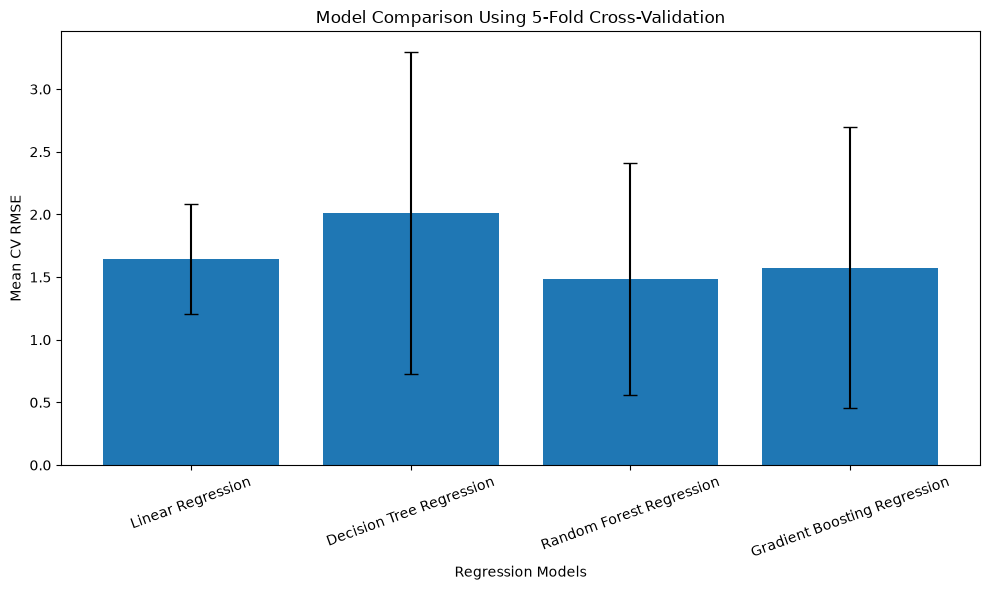

In [44]:
plt.figure(figsize=(10, 6))

plt.bar(
    cv_comparison["Model"],
    cv_comparison["Mean CV RMSE"],
    yerr=cv_comparison["Std CV RMSE"],
    capsize=5
)

plt.title("Model Comparison Using 5-Fold Cross-Validation")
plt.xlabel("Regression Models")
plt.ylabel("Mean CV RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

#### 6.19.1 Cross-Validation Visualization Findings

The cross-validation performance chart provides a visual comparison of the four regression models based on their mean RMSE and standard deviation across five folds.

Random Forest Regression achieved the lowest mean RMSE, indicating the best average validation performance. Gradient Boosting Regression also performed well, with a mean RMSE close to that of Random Forest.

Linear Regression showed the smallest error bars, suggesting more consistent performance across the validation folds. Decision Tree Regression had the highest mean RMSE and the greatest variation, indicating less consistent predictive performance.

Overall, the visualization supports the cross-validation results: Random Forest Regression is the leading candidate based on average RMSE, while Linear Regression demonstrates greater consistency across folds.

### 6.20 Individual Cross-Validation Fold Analysis

In [45]:
fold_results = []

for model_name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    rmse_scores = -scores

    for fold_number, score in enumerate(rmse_scores, start=1):
        fold_results.append({
            "Model": model_name,
            "Fold": fold_number,
            "RMSE": score
        })

fold_comparison = pd.DataFrame(fold_results)

display(
    fold_comparison.pivot(
        index="Fold",
        columns="Model",
        values="RMSE"
    ).round(4)
)

Model,Decision Tree Regression,Gradient Boosting Regression,Linear Regression,Random Forest Regression
Fold,,,,
1,1.4292,1.0910,1.8811,1.2170
2,3.2677,3.7030,2.3864,3.1395
3,0.7243,0.6360,1.1601,0.5601
4,3.8162,1.6627,1.3450,1.7654
5,0.8253,0.7802,1.4671,0.7431


#### 6.20.1 Individual Fold Analysis Findings

The individual fold results show noticeable variation in model performance across the five validation folds.

Fold 2 produced relatively high RMSE values for all four models, suggesting that the observations in this validation subset may be more challenging to predict. Fold 4 also resulted in a particularly high RMSE for Decision Tree Regression.

Random Forest Regression achieved strong results in Folds 1, 3, and 5 but showed increased prediction error in Fold 2. Linear Regression demonstrated comparatively more consistent performance across the folds.

These findings indicate that model performance varies depending on the validation data. Further investigation of the target-variable distribution across folds is necessary to understand whether certain subsets contain higher-priced or more difficult-to-predict vehicles.

### 6.21 Target Variable Distribution Across Folds

In [46]:
fold_target_summary = []

for fold_number, (_, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    y_fold = y_train.iloc[val_idx]

    fold_target_summary.append({
        "Fold": fold_number,
        "Count": len(y_fold),
        "Mean Selling Price": y_fold.mean(),
        "Median Selling Price": y_fold.median(),
        "Minimum Selling Price": y_fold.min(),
        "Maximum Selling Price": y_fold.max(),
        "Standard Deviation": y_fold.std()
    })

fold_target_df = pd.DataFrame(fold_target_summary)

display(fold_target_df.round(4))

,Fold,Count,Mean Selling Price,Median Selling Price,Minimum Selling Price,Maximum Selling Price,Standard Deviation
0,1,48,4.7804,3.400,0.15,20.75,4.8131
1,2,48,5.1335,2.925,0.18,35.00,6.7217
2,3,48,4.4985,4.250,0.10,23.50,4.4209
3,4,48,4.2446,3.505,0.20,19.99,4.3072
4,5,47,4.2545,3.490,0.20,23.00,4.2388


#### 6.21.1 Target Variable Distribution Findings

The selling-price distribution across the five validation folds was examined to investigate the variation in cross-validation performance.

Fold 2 recorded the highest mean selling price (5.1335), maximum selling price (35.00), and standard deviation (6.7217). Its median selling price was 2.925, which was lower than the medians of the other folds.

The difference between its mean and median, together with its higher maximum value and standard deviation, suggests that Fold 2 contains some relatively expensive vehicles that contribute to a wider price distribution.

This observation may help explain why all four regression models recorded higher RMSE values on Fold 2. However, further inspection of the individual observations is required before drawing a definite conclusion.

Overall, the analysis highlights the importance of examining target-variable distributions when evaluating model performance across different validation folds.

### 6.22 Inspection of High-Priced Observations in Fold 2

In [47]:
# Retrieve the validation indices for Fold 2
fold_splits = list(cv.split(X_train, y_train))
_, fold_2_val_idx = fold_splits[1]

# Extract Fold 2 features and target values
fold_2_data = X_train.iloc[fold_2_val_idx].copy()
fold_2_data["Selling_Price"] = y_train.iloc[fold_2_val_idx]

# Display the 10 most expensive cars
display(
    fold_2_data
    .sort_values(by="Selling_Price", ascending=False)
    .head(10)
)

,Year,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Selling_Price
86,2010,92.60,78000,Diesel,Dealer,Manual,0,35.00
82,2017,25.39,15000,Diesel,Dealer,Automatic,0,23.00
66,2017,23.15,11000,Petrol,Dealer,Automatic,0,19.75
97,2017,18.64,8700,Petrol,Dealer,Manual,0,17.00
69,2016,20.91,12000,Petrol,Dealer,Manual,0,14.25
276,2015,13.60,24800,Petrol,Dealer,Manual,0,8.65
288,2015,13.60,34000,Petrol,Dealer,Manual,0,8.40
258,2015,13.60,25000,Petrol,Dealer,Manual,0,8.40
223,2015,9.40,61381,Diesel,Dealer,Manual,0,8.25
285,2016,8.50,15059,Petrol,Dealer,Automatic,0,7.40


#### 6.22.1 High-Priced Observation Analysis

The ten highest-selling-price observations in Fold 2 were examined to investigate the potential reasons behind its higher prediction errors.

The most expensive vehicle had a present price of 92.60 and a selling price of 35.00. Other high-priced vehicles also showed relatively high present prices, ranging from 18.64 to 25.39 among the next four observations.

These findings suggest that Fold 2 contains several expensive vehicles, including an observation with a particularly high present price. Such observations may be more difficult for regression models to predict accurately, especially when similar examples are limited in the training data.

However, high values should not automatically be treated as errors or removed. The observations will be retained unless further investigation identifies a data-quality issue.

### 6.23 Prediction Error Analysis for High-Priced Vehicles

In [48]:
from sklearn.model_selection import cross_val_predict

# Generate out-of-fold predictions for each model
oof_predictions = {}

for model_name, model in models.items():
    oof_predictions[model_name] = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict"
    )

# Retrieve Fold 2 validation indices
fold_2_indices = fold_splits[1][1]

# Build a comparison using only Fold 2 observations
fold_2_cv_predictions = X_train.iloc[fold_2_indices].copy()

fold_2_cv_predictions["Actual_Price"] = (
    y_train.iloc[fold_2_indices].values
)

for model_name, predictions in oof_predictions.items():
    fold_2_cv_predictions[model_name] = predictions[fold_2_indices]

# Display the ten most expensive vehicles
display(
    fold_2_cv_predictions
    .sort_values(by="Actual_Price", ascending=False)
    [[
        "Present_Price",
        "Actual_Price",
        "Decision Tree Regression",
        "Random Forest Regression",
        "Gradient Boosting Regression",
        "Linear Regression"
    ]]
    .head(10)
    .round(4)
)

,Present_Price,Actual_Price,Decision Tree Regression,Random Forest Regression,Gradient Boosting Regression,Linear Regression
86,92.60,35.00,14.50,14.5377,10.9381,47.0131
82,25.39,23.00,18.00,18.7833,20.0783,16.8637
66,23.15,19.75,18.00,17.6332,17.9529,14.5397
97,18.64,17.00,14.73,12.5825,10.0955,11.4492
69,20.91,14.25,20.75,15.3172,17.0079,12.2376
276,13.60,8.65,8.50,9.7721,9.8090,8.0938
288,13.60,8.40,8.50,9.2179,9.4700,7.9975
258,13.60,8.40,8.50,9.7721,9.8090,8.0917
223,9.40,8.25,5.95,6.7605,6.7178,6.8279
285,8.50,7.40,6.75,7.0445,7.4260,6.7848


#### 6.23.1 Out-of-Fold Prediction Analysis

Out-of-fold predictions were generated to examine how the four regression models perform on previously unseen observations within Fold 2.

The results show that the vehicle with the highest actual selling price (35.00) was particularly difficult for all four models to predict. Decision Tree, Random Forest, and Gradient Boosting substantially underpredicted its selling price, while Linear Regression overpredicted it.

The other high-priced vehicles showed varying prediction errors across the models. Random Forest and Gradient Boosting produced relatively accurate predictions for some observations, while Linear Regression performed better on the most expensive vehicle than the other three models, although its prediction error remained substantial.

These findings suggest that certain high-priced vehicles contribute to the prediction difficulty observed in Fold 2. However, the results also demonstrate that prediction errors are not limited to the most expensive observations.

Out-of-fold predictions provide a more reliable assessment of validation performance because each observation is predicted by a model that was not trained on it.

### 6.24 Analysis of the Largest Prediction Errors

In [49]:
# Calculate absolute prediction errors for each model
error_analysis = fold_2_cv_predictions[
    ["Actual_Price"]
].copy()

for model_name in models.keys():
    error_analysis[f"{model_name} Error"] = (
        fold_2_cv_predictions["Actual_Price"]
        - fold_2_cv_predictions[model_name]
    ).abs()

# Display the ten largest errors for each model
for model_name in models.keys():
    error_column = f"{model_name} Error"

    print(f"\nTop 10 Errors: {model_name}")

    display(
        error_analysis
        .sort_values(by=error_column, ascending=False)
        .head(10)
        .round(4)
    )


Top 10 Errors: Linear Regression


,Actual_Price,Linear Regression Error,Decision Tree Regression Error,Random Forest Regression Error,Gradient Boosting Regression Error
86,35.00,12.0131,20.50,20.4623,24.0619
82,23.00,6.1363,5.00,4.2167,2.9217
97,17.00,5.5508,2.27,4.4175,6.9045
66,19.75,5.2103,1.75,2.1168,1.7971
159,0.45,2.1407,0.03,0.0100,0.0776
69,14.25,2.0124,6.50,1.0672,2.7579
165,0.45,1.8703,0.05,0.0068,0.0565
223,8.25,1.4221,2.30,1.4895,1.5322
27,6.00,1.3600,0.25,0.7905,0.3827
39,2.25,1.2468,0.15,0.3215,0.0860



Top 10 Errors: Decision Tree Regression


,Actual_Price,Linear Regression Error,Decision Tree Regression Error,Random Forest Regression Error,Gradient Boosting Regression Error
86,35.00,12.0131,20.50,20.4623,24.0619
69,14.25,2.0124,6.50,1.0672,2.7579
82,23.00,6.1363,5.00,4.2167,2.9217
223,8.25,1.4221,2.30,1.4895,1.5322
97,17.00,5.5508,2.27,4.4175,6.9045
87,5.90,0.9711,1.80,0.1928,0.5047
284,3.50,0.2224,1.80,0.9110,0.6785
66,19.75,5.2103,1.75,2.1168,1.7971
210,3.10,0.6277,1.10,0.4075,0.7300
28,1.95,0.5417,1.00,0.7035,0.3526



Top 10 Errors: Random Forest Regression


,Actual_Price,Linear Regression Error,Decision Tree Regression Error,Random Forest Regression Error,Gradient Boosting Regression Error
86,35.00,12.0131,20.50,20.4623,24.0619
97,17.00,5.5508,2.27,4.4175,6.9045
82,23.00,6.1363,5.00,4.2167,2.9217
66,19.75,5.2103,1.75,2.1168,1.7971
223,8.25,1.4221,2.30,1.4895,1.5322
258,8.40,0.3083,0.10,1.3721,1.4090
276,8.65,0.5562,0.15,1.1221,1.1590
278,6.00,0.0108,0.40,1.1000,1.0489
69,14.25,2.0124,6.50,1.0672,2.7579
284,3.50,0.2224,1.80,0.9110,0.6785



Top 10 Errors: Gradient Boosting Regression


,Actual_Price,Linear Regression Error,Decision Tree Regression Error,Random Forest Regression Error,Gradient Boosting Regression Error
86,35.00,12.0131,20.50,20.4623,24.0619
97,17.00,5.5508,2.27,4.4175,6.9045
82,23.00,6.1363,5.00,4.2167,2.9217
69,14.25,2.0124,6.50,1.0672,2.7579
66,19.75,5.2103,1.75,2.1168,1.7971
223,8.25,1.4221,2.30,1.4895,1.5322
258,8.40,0.3083,0.10,1.3721,1.4090
276,8.65,0.5562,0.15,1.1221,1.1590
288,8.40,0.4025,0.10,0.8179,1.0700
278,6.00,0.0108,0.40,1.1000,1.0489


#### Findings

The absolute error analysis of Fold 2 revealed that certain observations contribute disproportionately to prediction errors across the regression models.

The vehicle at index 86, with an actual selling price of 35.00, was particularly difficult to predict. All four models produced substantial errors for this observation, although Linear Regression had the smallest absolute error among them.

Other relatively expensive vehicles, including those at indices 82, 97, 66, and 69, also appeared frequently among the largest prediction errors. However, large errors were not restricted to expensive vehicles. Linear Regression also showed relatively high errors for some low-priced observations, such as indices 159 and 165, where the other models performed considerably better.

The results demonstrate that model performance varies across individual observations. No single regression algorithm consistently produces the smallest error for every vehicle. Therefore, overall evaluation metrics and cross-validation results remain important when comparing and selecting models.

### 6.25 Inspecting Features of High-Error Observations

#### 6.25.1 Display observations with the largest errors

In [50]:
# Original feature columns
feature_columns = X_train.columns.tolist()

# Inspect the five largest errors for each model
for model_name in models.keys():

    error_column = f"{model_name} Error"

    top_error_indices = (
        error_analysis[error_column]
        .nlargest(5)
        .index
    )

    print(f"\nTop 5 High-Error Observations: {model_name}")

    display(
        fold_2_cv_predictions
        .loc[top_error_indices, feature_columns + [
            "Actual_Price",
            model_name
        ]]
        .assign(
            Absolute_Error=error_analysis.loc[
                top_error_indices, error_column
            ]
        )
        .round(4)
    )


Top 5 High-Error Observations: Linear Regression


,Year,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Actual_Price,Linear Regression,Absolute_Error
86,2010,92.60,78000,Diesel,Dealer,Manual,0,35.00,47.0131,12.0131
82,2017,25.39,15000,Diesel,Dealer,Automatic,0,23.00,16.8637,6.1363
97,2017,18.64,8700,Petrol,Dealer,Manual,0,17.00,11.4492,5.5508
66,2017,23.15,11000,Petrol,Dealer,Automatic,0,19.75,14.5397,5.2103
159,2017,0.51,4000,Petrol,Individual,Automatic,0,0.45,2.5907,2.1407



Top 5 High-Error Observations: Decision Tree Regression


,Year,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Actual_Price,Decision Tree Regression,Absolute_Error
86,2010,92.60,78000,Diesel,Dealer,Manual,0,35.00,14.50,20.50
69,2016,20.91,12000,Petrol,Dealer,Manual,0,14.25,20.75,6.50
82,2017,25.39,15000,Diesel,Dealer,Automatic,0,23.00,18.00,5.00
223,2015,9.40,61381,Diesel,Dealer,Manual,0,8.25,5.95,2.30
97,2017,18.64,8700,Petrol,Dealer,Manual,0,17.00,14.73,2.27



Top 5 High-Error Observations: Random Forest Regression


,Year,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Actual_Price,Random Forest Regression,Absolute_Error
86,2010,92.60,78000,Diesel,Dealer,Manual,0,35.00,14.5377,20.4623
97,2017,18.64,8700,Petrol,Dealer,Manual,0,17.00,12.5825,4.4175
82,2017,25.39,15000,Diesel,Dealer,Automatic,0,23.00,18.7833,4.2167
66,2017,23.15,11000,Petrol,Dealer,Automatic,0,19.75,17.6332,2.1168
223,2015,9.40,61381,Diesel,Dealer,Manual,0,8.25,6.7605,1.4895



Top 5 High-Error Observations: Gradient Boosting Regression


,Year,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Actual_Price,Gradient Boosting Regression,Absolute_Error
86,2010,92.60,78000,Diesel,Dealer,Manual,0,35.00,10.9381,24.0619
97,2017,18.64,8700,Petrol,Dealer,Manual,0,17.00,10.0955,6.9045
82,2017,25.39,15000,Diesel,Dealer,Automatic,0,23.00,20.0783,2.9217
69,2016,20.91,12000,Petrol,Dealer,Manual,0,14.25,17.0079,2.7579
66,2017,23.15,11000,Petrol,Dealer,Automatic,0,19.75,17.9529,1.7971


#### Findings

Inspection of the original feature values revealed that several observations consistently produced large prediction errors across multiple regression models.

The vehicle at index 86 was particularly difficult to predict. It had a Present_Price of 92.60, a manufacturing year of 2010, and an actual Selling_Price of 35.00. Linear Regression substantially overestimated its selling price, whereas Decision Tree, Random Forest, and Gradient Boosting substantially underestimated it.

Other relatively expensive vehicles at indices 82, 97, and 66 also appeared frequently among the largest prediction errors. This indicates that the models have difficulty predicting certain high-priced vehicles.

However, the inspected observations differ in their manufacturing years, mileage, fuel types, and transmission types. Therefore, no single feature can be identified as the direct cause of these prediction errors from this analysis alone.

Overall, the feature inspection suggests that some individual vehicles are particularly challenging to predict. These observations highlight the importance of evaluating model performance across different price ranges rather than relying only on overall evaluation metrics.

### 6.26 Final Model Comparison and Selection

#### 6.26.1 Combine test-set and cross-validation results

In [51]:
# Select and rename test-set metrics
test_comparison = model_comparison[
    ["Model", "MAE", "RMSE", "R2 Score"]
].rename(columns={
    "MAE": "Test MAE",
    "RMSE": "Test RMSE",
    "R2 Score": "Test R2"
})

# Combine test results with cross-validation results
final_comparison = test_comparison.merge(
    cv_comparison,
    on="Model",
    how="inner"
)

# Rank models by mean cross-validation RMSE
final_comparison = (
    final_comparison
    .sort_values("Mean CV RMSE")
    .reset_index(drop=True)
)

display(final_comparison.round(4))

,Model,Test MAE,Test RMSE,Test R2,Mean CV RMSE,Std CV RMSE
0,Random Forest Regression,1.5448,3.7864,0.4437,1.4850,0.9267
1,Gradient Boosting Regression,1.1473,2.5314,0.7514,1.5746,1.1210
2,Linear Regression,1.4725,2.5245,0.7527,1.6479,0.4387
3,Decision Tree Regression,1.1048,2.0957,0.8296,2.0125,1.2836


#### 6.26.2 Final Comparison Findings

The results show different model rankings across the two evaluation methods. Decision Tree Regression achieved the lowest test-set RMSE of 2.0957, while Random Forest Regression achieved the lowest mean cross-validation RMSE of 1.4850. Gradient Boosting Regression achieved a test-set RMSE of 2.5314 and a mean cross-validation RMSE of 1.5746.

Gradient Boosting was retained as a practical compromise, rather than being considered the objectively best model. Since test-set results were considered during model selection, the test-set metrics should be interpreted with caution as an estimate of final generalization performance.

### 6.27 Final Evaluation of the Selected Model

#### 6.27.1 Generate final predictions and calculate metrics

In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Use the existing fitted Gradient Boosting pipeline
final_predictions = gradient_boosting_model.predict(X_test)

# Calculate test-set evaluation metrics
final_mae = mean_absolute_error(y_test, final_predictions)
final_mse = mean_squared_error(y_test, final_predictions)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, final_predictions)

# Display final model performance
final_model_metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2"],
    "Value": [final_mae, final_mse, final_rmse, final_r2]
})

display(final_model_metrics.round(4))

,Metric,Value
0,MAE,1.1473
1,MSE,6.4080
2,RMSE,2.5314
3,R2,0.7514


#### 6.27.2 Actual vs. predicted prices

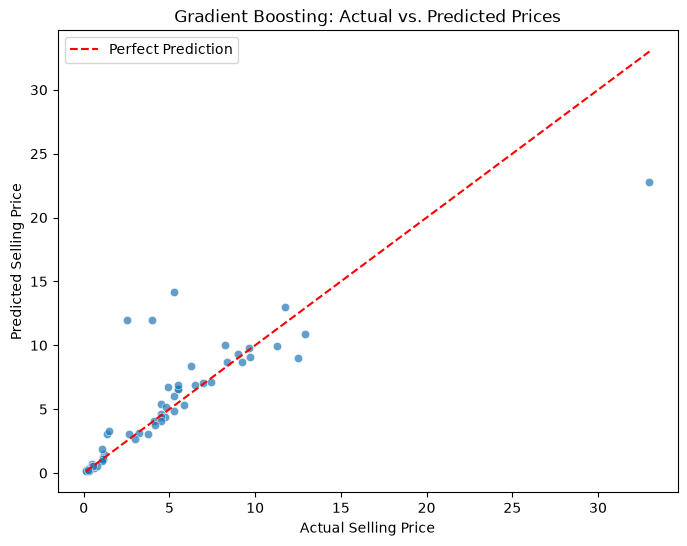

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=final_predictions,
    alpha=0.7
)

# Reference line for perfect predictions
min_price = min(y_test.min(), final_predictions.min())
max_price = max(y_test.max(), final_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Gradient Boosting: Actual vs. Predicted Prices")
plt.legend()
plt.show()

#### 6.27.3 Residual analysis

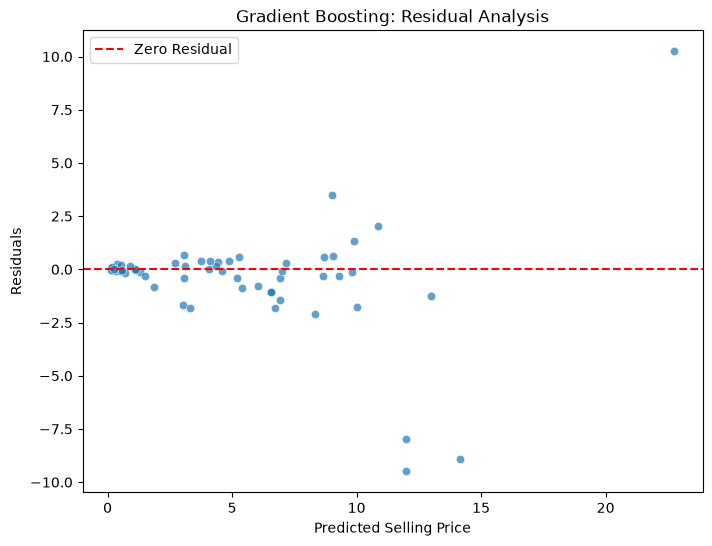

In [54]:
# Calculate residuals
final_residuals = y_test - final_predictions

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=final_predictions,
    y=final_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Residual"
)

plt.xlabel("Predicted Selling Price")
plt.ylabel("Residuals")
plt.title("Gradient Boosting: Residual Analysis")
plt.legend()
plt.show()

#### Findings

The Gradient Boosting Regression model achieved a Mean Absolute Error (MAE) of 1.1473, Mean Squared Error (MSE) of 6.4080, Root Mean Squared Error (RMSE) of 2.5314, and R² score of 0.7514 on the test dataset.

The actual-versus-predicted plot showed that many predictions were reasonably close to their actual selling prices, particularly for lower-priced vehicles. However, the model overestimated some lower-priced vehicles and substantially underestimated the most expensive test observation.

The residual plot showed that many errors were concentrated around zero, but some observations had considerably larger positive or negative residuals. The spread of residuals also increased for certain higher predicted prices, suggesting that prediction errors were not uniform across the entire price range.

Overall, Gradient Boosting demonstrated reasonable predictive performance but still struggled with certain individual vehicles, particularly some observations with higher selling prices. These limitations should be considered when interpreting its predictions.

### 6.28 Final Model Selection

#### 6.28.1 Assign the final model

In [55]:
# Select the final model
final_model = gradient_boosting_model

# Display final model performance
print("Selected Model: Gradient Boosting Regression")
print(f"MAE:  {final_mae:.4f}")
print(f"MSE:  {final_mse:.4f}")
print(f"RMSE: {final_rmse:.4f}")
print(f"R2:   {final_r2:.4f}")

Selected Model: Gradient Boosting Regression
MAE:  1.1473
MSE:  6.4080
RMSE: 2.5314
R2:   0.7514


#### Findings

The comparison of four regression algorithms showed different performance rankings between the held-out test set and five-fold cross-validation.

Decision Tree Regression achieved the lowest test-set RMSE of 2.0957 and the highest test-set R² score of 0.8296. Random Forest Regression achieved the lowest mean cross-validation RMSE of 1.4850, while Gradient Boosting Regression ranked second with a mean cross-validation RMSE of 1.5746.

Gradient Boosting achieved a test-set RMSE of 2.5314 and an R² score of 0.7514. Although it did not achieve the best result in either evaluation, it provided a reasonable compromise between cross-validation and test-set performance.

Gradient Boosting Regression was therefore retained as the project's selected model. This is a practical project-level choice rather than evidence that it is statistically superior to the other algorithms. The differences between the evaluation results also highlight the importance of further validation using additional data.

---

# 7. Conclusion

## 7.1 Project Summary

The objective of this project was to develop a machine learning model capable of predicting used car selling prices based on available vehicle characteristics.

The project followed a complete regression workflow, beginning with data inspection and cleaning, followed by exploratory data analysis, feature preparation, model training, and performance evaluation.

The original dataset contained 301 observations and 9 columns. During data cleaning, missing values, duplicate records, inconsistent whitespace, and potential invalid numerical values were inspected. Two duplicate records were removed, resulting in a cleaned dataset containing 299 observations.

Exploratory Data Analysis helped identify relationships between vehicle characteristics and selling prices. Present Price showed a strong positive correlation with Selling Price, while other features demonstrated weaker relationships or differences across categories.

Four regression algorithms were trained and evaluated:
- Linear Regression
- Decision Tree Regression
- Random Forest Regression
- Gradient Boosting Regression

The models were evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R². Five-fold cross-validation was also performed using the training dataset to examine model performance across different validation splits.

## 7.2 Selected Model Performance on the Held-Out Test Set

Gradient Boosting Regression was selected as the final model because it provided a reasonable balance between test-set and cross-validation performance.

Its final test-set evaluation produced the following results:

| Evaluation Metric | Result |
|---|---:|
| MAE | 1.1473 |
| MSE | 6.4080 |
| RMSE | 2.5314 |
| R² | 0.7514 |

The R² score indicates that the model explains approximately 75.14% of the variation in selling prices in the test dataset.

Because the test-set results were also considered during model selection, these metrics should be interpreted cautiously rather than as a completely independent final evaluation.

## 7.3 Key Findings

- Present Price was strongly positively correlated with Selling Price.
- Vehicle age and mileage were examined as potential predictors, but their individual linear correlations with Selling Price were relatively weak.
- Selling prices varied across fuel types, selling types, and transmission categories.
- Decision Tree Regression achieved the best performance on the held-out test dataset.
- Random Forest Regression achieved the lowest mean RMSE during cross-validation.
- Gradient Boosting provided a reasonable balance between the two evaluation methods and was selected as the final model.
- Error analysis revealed that some individual vehicles, particularly certain higher-priced observations, were difficult for the models to predict accurately.

## 7.4 Project Limitations

Although the selected model demonstrated reasonable predictive performance, several limitations should be considered:

- The dataset contains only 299 observations after cleaning, which limits the amount of information available for model training.
- The dataset includes a limited set of vehicle characteristics. Additional features could improve prediction quality.
- Some individual observations produced substantial prediction errors, particularly among higher-priced vehicles.
- The model was evaluated using one train-test split and five-fold cross-validation. Further validation on independent datasets would provide stronger evidence of its generalization ability.
- The initial modeling approach excluded Car_Name because it contained many distinct categories. Further feature engineering could investigate whether this information improves prediction performance.

## 7.5 Future Improvements

The project could be improved through the following steps:

- Collect a larger and more diverse used-car dataset.
- Explore additional vehicle characteristics, such as brand, model, engine capacity, and vehicle condition.
- Investigate feature engineering techniques to extract more useful information from existing features.
- Perform hyperparameter tuning for the regression algorithms.
- Experiment with additional regression models and compare their performance.
- Evaluate the selected model on an independent external dataset.

## 7.6 Final Remarks

This project provided practical experience with the complete machine learning workflow for a regression problem. It demonstrated the importance of data quality checks, exploratory analysis, feature preparation, model comparison, cross-validation, and error analysis.

The results show that machine learning can be used to estimate used-car selling prices based on available vehicle information. However, predictions should be interpreted with consideration of the dataset's limitations and the errors observed during evaluation.